In [ ]:
# Imports
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from sklearn.metrics import (
    accuracy_score, f1_score,
    classification_report, confusion_matrix)
import torch

print(f" Libraries imported")
print(f" Device : {'GPU ' if torch.cuda.is_available() else 'CPU'}")

 Libraries imported
 Device : CPU


In [ ]:
#  Load test data
test_df = pd.read_csv("../data/processed/test_data.csv")

#  Label encoding
label2id = {"negative": 0, "neutral": 1, "positive": 2}
id2label = {0: "negative", 1: "neutral", 2: "positive"}

test_df["label"] = test_df["sentiment"].map(label2id)

print(f" Test data loaded : {len(test_df)} rows")
print(f"\n Distribution :\n{test_df['sentiment'].value_counts()}")

 Test data loaded : 840 rows

 Distribution :
sentiment
neutral     301
positive    276
negative    263
Name: count, dtype: int64


In [ ]:
# Prediction function
def predict(texts, model_path, batch_size=32):
    tokenizer = AutoTokenizer.from_pretrained(model_path)
    model     = AutoModelForSequenceClassification.from_pretrained(model_path)
    model.eval()

    all_preds = []

    for i in range(0, len(texts), batch_size):
        batch = texts[i:i+batch_size].tolist()
        inputs = tokenizer(
            batch,
            padding=True,
            truncation=True,
            max_length=128,
            return_tensors="pt")
        with torch.no_grad():
            outputs = model(**inputs)
        preds = torch.argmax(outputs.logits, dim=-1).numpy()
        all_preds.extend(preds)

    return np.array(all_preds)

print("Prediction function defined")

Prediction function defined


In [ ]:
#  Define models
MODELS = {
    "XLM-RoBERTa" : "../models/xlm-roberta-base-finetuned",
    "mBERT"        : "../models/mbert-finetuned",
    "DarijaBERT"   : "../models/darijaBERT-finetuned"
}

true_labels = test_df["label"].values
texts       = test_df["text"]

# Run predictions
results = {}

for model_name, model_path in MODELS.items():
    print(f"\nEvaluating : {model_name}")
    preds = predict(texts, model_path)
    
    results[model_name] = {
        "predictions" : preds,
        "accuracy"    : accuracy_score(true_labels, preds),
        "f1_macro"    : f1_score(true_labels, preds, average="macro"),
        "f1_weighted" : f1_score(true_labels, preds, average="weighted")
    }
    print(f" Accuracy : {results[model_name]['accuracy']:.4f}")
    print(f" F1 Macro : {results[model_name]['f1_macro']:.4f}")


Evaluating : XLM-RoBERTa


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 Accuracy : 0.8429
 F1 Macro : 0.8421

Evaluating : mBERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 Accuracy : 0.8345
 F1 Macro : 0.8341

Evaluating : DarijaBERT


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

 Accuracy : 0.8167
 F1 Macro : 0.8167


In [ ]:
# Comparison table
comparison = pd.DataFrame({
    "Model"       : list(results.keys()),
    "Accuracy"    : [results[m]["accuracy"] for m in results],
    "F1 Macro"    : [results[m]["f1_macro"] for m in results],
    "F1 Weighted" : [results[m]["f1_weighted"] for m in results]
})

comparison = comparison.sort_values("F1 Macro", ascending=False).reset_index(drop=True)
comparison["Rank"] = comparison.index + 1

print("-" * 55)
print("MODEL COMPARISON")
print("-" * 55)
print(comparison.to_string(index=False))
print(f"\n Best model : {comparison.iloc[0]['Model']}")

-------------------------------------------------------
MODEL COMPARISON
-------------------------------------------------------
      Model  Accuracy  F1 Macro  F1 Weighted  Rank
XLM-RoBERTa  0.842857  0.842142     0.841854     1
      mBERT  0.834524  0.834107     0.833932     2
 DarijaBERT  0.816667  0.816670     0.816244     3

 Best model : XLM-RoBERTa


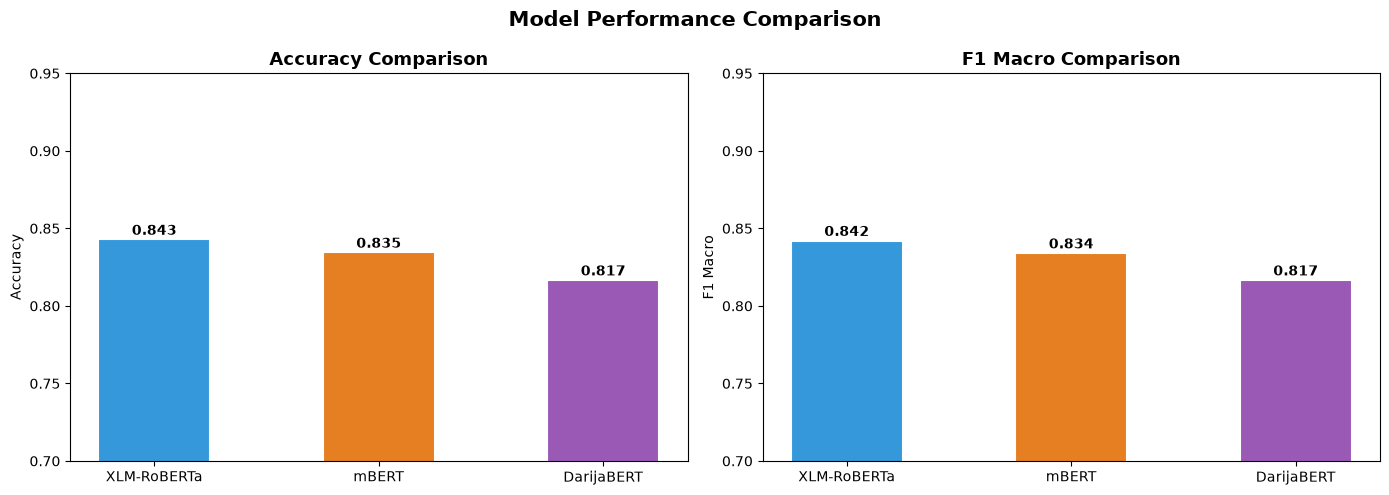

In [ ]:
# Visualization — Model comparison
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

models  = list(results.keys())
colors  = ["#3498db", "#e67e22", "#9b59b6"]

# Accuracy
bars = axes[0].bar(models, 
                   [results[m]["accuracy"] for m in models],
                   color=colors, edgecolor="white", linewidth=1.5, width=0.5)
axes[0].set_title("Accuracy Comparison", fontweight="bold", fontsize=13)
axes[0].set_ylabel("Accuracy")
axes[0].set_ylim(0.7, 0.95)
for bar, m in zip(bars, models):
    v = results[m]["accuracy"]
    axes[0].text(bar.get_x() + bar.get_width()/2,
                 v + 0.003, f"{v:.3f}", ha="center", fontweight="bold")

# F1 Macro
bars = axes[1].bar(models,
                   [results[m]["f1_macro"] for m in models],
                   color=colors, edgecolor="white", linewidth=1.5, width=0.5)
axes[1].set_title("F1 Macro Comparison", fontweight="bold", fontsize=13)
axes[1].set_ylabel("F1 Macro")
axes[1].set_ylim(0.7, 0.95)
for bar, m in zip(bars, models):
    v = results[m]["f1_macro"]
    axes[1].text(bar.get_x() + bar.get_width()/2,
                 v + 0.003, f"{v:.3f}", ha="center", fontweight="bold")

plt.suptitle("Model Performance Comparison", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/processed/model_comparison.png", dpi=150, bbox_inches="tight")
plt.show()

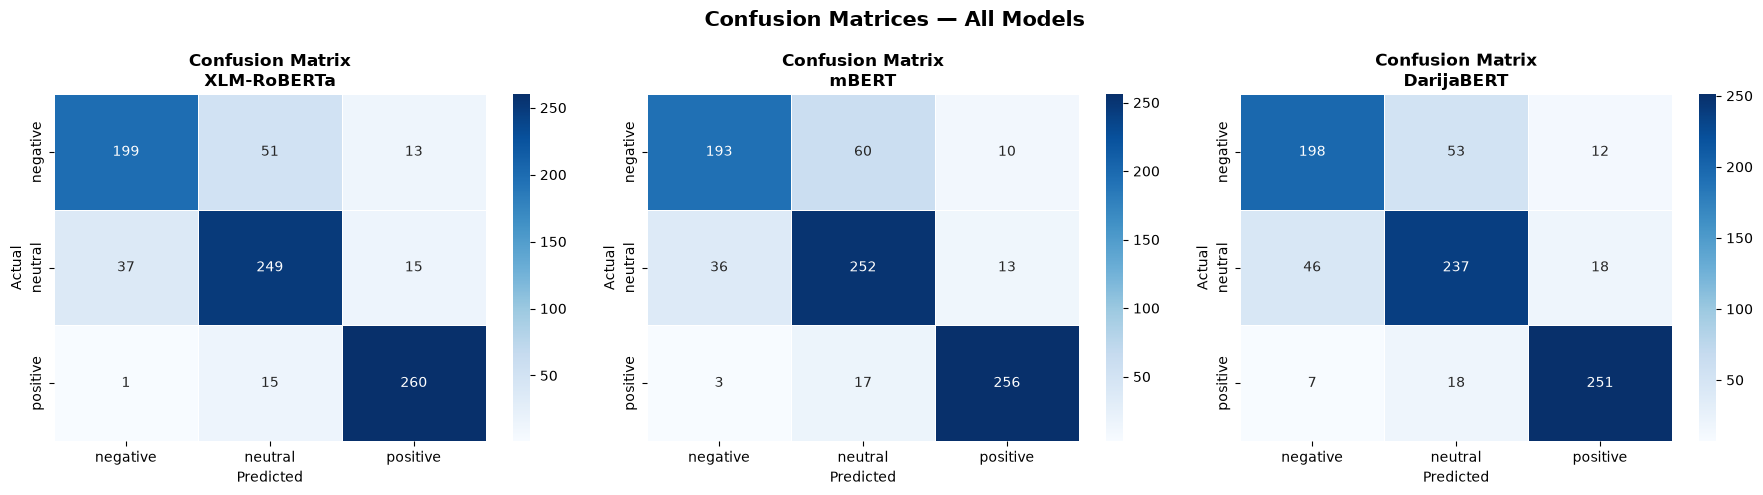

In [ ]:
# Confusion matrices for all models
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
labels_names = ["negative", "neutral", "positive"]

for idx, (model_name, result) in enumerate(results.items()):
    cm = confusion_matrix(true_labels, result["predictions"])
    
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=labels_names,
        yticklabels=labels_names,
        ax=axes[idx], linewidths=0.5
    )
    axes[idx].set_title(f"Confusion Matrix\n{model_name}", fontweight="bold")
    axes[idx].set_xlabel("Predicted")
    axes[idx].set_ylabel("Actual")

plt.suptitle("Confusion Matrices — All Models", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/processed/confusion_matrices.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# Detailed classification reports
for model_name, result in results.items():
    print(f"\n{'='*50}")
    print(f"CLASSIFICATION REPORT — {model_name}")
    print(f"{'-'*50}")
    print(classification_report(
        true_labels,
        result["predictions"],
        target_names=labels_names
    ))


CLASSIFICATION REPORT — XLM-RoBERTa
--------------------------------------------------
              precision    recall  f1-score   support

    negative       0.84      0.76      0.80       263
     neutral       0.79      0.83      0.81       301
    positive       0.90      0.94      0.92       276

    accuracy                           0.84       840
   macro avg       0.84      0.84      0.84       840
weighted avg       0.84      0.84      0.84       840


CLASSIFICATION REPORT — mBERT
--------------------------------------------------
              precision    recall  f1-score   support

    negative       0.83      0.73      0.78       263
     neutral       0.77      0.84      0.80       301
    positive       0.92      0.93      0.92       276

    accuracy                           0.83       840
   macro avg       0.84      0.83      0.83       840
weighted avg       0.84      0.83      0.83       840


CLASSIFICATION REPORT — DarijaBERT
--------------------------------

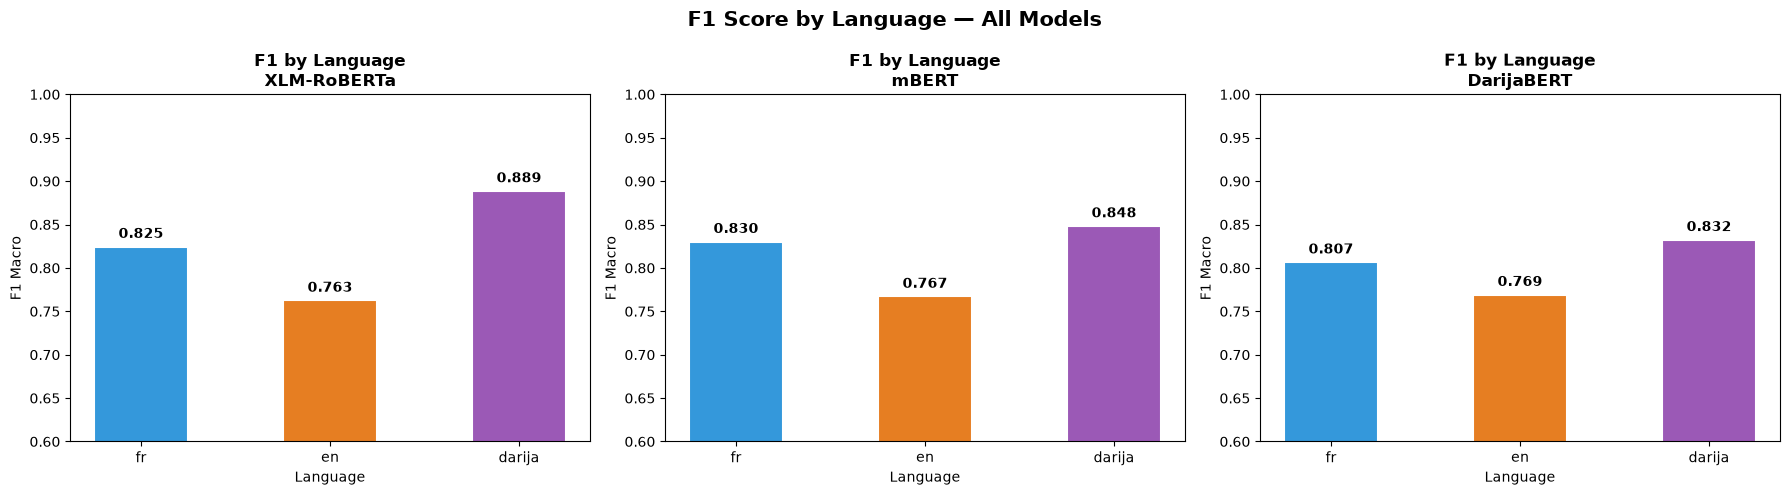

In [ ]:
#  Performance by language
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

for idx, (model_name, result) in enumerate(results.items()):
    lang_f1 = {}
    for lang in ["fr", "en", "darija"]:
        mask      = test_df["language"] == lang
        y_true    = true_labels[mask]
        y_pred    = result["predictions"][mask]
        lang_f1[lang] = f1_score(y_true, y_pred, average="macro")

    lang_colors = ["#3498db", "#e67e22", "#9b59b6"]
    bars = axes[idx].bar(
        lang_f1.keys(), lang_f1.values(),
        color=lang_colors, edgecolor="white", linewidth=1.5, width=0.5
    )
    axes[idx].set_title(f"F1 by Language\n{model_name}", fontweight="bold")
    axes[idx].set_xlabel("Language")
    axes[idx].set_ylabel("F1 Macro")
    axes[idx].set_ylim(0.6, 1.0)
    for bar, v in zip(bars, lang_f1.values()):
        axes[idx].text(bar.get_x() + bar.get_width()/2,
                       v + 0.01, f"{v:.3f}", ha="center", fontweight="bold")

plt.suptitle("F1 Score by Language — All Models", fontsize=15, fontweight="bold")
plt.tight_layout()
plt.savefig("../data/processed/f1_by_language.png", dpi=150, bbox_inches="tight")
plt.show()

In [ ]:
# final evaluation summary

best_model = comparison.iloc[0]["Model"]
best_acc = comparison.iloc[0]["Accuracy"]
best_f1 = comparison.iloc[0]["F1 Macro"]

print("=" * 50)
print("FINAL EVALUATION SUMMARY")
print("=" * 50)

print(f"\n{'Model':<15} {'Accuracy':<12} {'F1 Macro':<12}")
print("-" * 40)

for _, row in comparison.iterrows():
    marker = " (Best)" if row["Model"] == best_model else ""
    print(
        f"{row['Model']:<15} "
        f"{row['Accuracy']:<12.4f} "
        f"{row['F1 Macro']:<12.4f}"
        f"{marker}"
    )

print(f"\nBest model : {best_model}")
print(f"Accuracy   : {best_acc:.4f}")
print(f"F1 Macro   : {best_f1:.4f}")
print(f"\nSelected model for deployment: {best_model}")

FINAL EVALUATION SUMMARY

Model           Accuracy     F1 Macro    
----------------------------------------
XLM-RoBERTa     0.8429       0.8421       (Best)
mBERT           0.8345       0.8341      
DarijaBERT      0.8167       0.8167      

Best model : XLM-RoBERTa
Accuracy   : 0.8429
F1 Macro   : 0.8421

Selected model for deployment: XLM-RoBERTa
